In [1]:
import sys
from pathlib import Path

# Get the project root assuming the notebook is one level deep in the notebooks folder
project_root = Path().resolve().parent

for folder in ["src",]:

    src_path = project_root / folder
    if str(src_path) not in sys.path:
        sys.path.insert(0, str(src_path))

# Example 1 - Solar house with battery

In [2]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from fennec.fennec import run
from fennec.utils import get_detailed_results
from fennec.examples.example_01 import get_data

In [3]:
data = get_data()

In [4]:
results, instance = run(data, time_limit=30, mip_abs_gap = 0.01, mip_rel_gap=0.01)
instance.solutions.load_from(results)

ERROR:root:Failed to run optimization


In [5]:
detailed_results = get_detailed_results(results, instance)
df_parameters = pd.DataFrame(detailed_results["Parameters"])
df_variables = pd.DataFrame(detailed_results["Variables"])
df_sets = pd.DataFrame(detailed_results["Sets"])

In [6]:
def get_set(df, name):
    return df[df['Set'] == name]['Value'].values
def get_variable(df, name):
    return df[df['Variable'] == name]['Value'].values

def get_parameter(df, name):
    return df[df['Parameter'] == name]['Value'].values

In [7]:
t = get_set(df_sets, 't')
grid_to = get_variable(df_variables, 'grid.energy_to')
grid_from = get_variable(df_variables, 'grid.energy_from')
tariff_to = get_parameter(df_parameters, 'grid.tariff_energy_from')
tariff_from = get_parameter(df_parameters, 'grid.tariff_energy_to')
load_to = get_parameter(df_parameters, 'node[LOAD01].energy_to')
load_from = get_parameter(df_parameters, 'node[LOAD01].energy_from')
pv_to = get_parameter(df_parameters, 'node[PV01].energy_to')
pv_from = get_parameter(df_parameters, 'node[PV01].energy_from')

solar_surplus = get_variable(df_variables, 'storageController[CONT01].solar_surplus')
solar_deficit = get_variable(df_variables, 'storageController[CONT01].solar_deficit')

flag_arbitrage = get_variable(df_variables, 'storageController[CONT01].flag_arbitrage')
charge_arbitrage = get_variable(df_variables, 'storageController[CONT01].charge_arbitrage')
discharge_arbitrage = get_variable(df_variables, 'storageController[CONT01].discharge_arbitrage')

soc = get_variable(df_variables, 'storage[BAT01].soc')
soc_specifications = get_parameter(df_parameters, 'storageController[CONT01].soc_specifications')
charge = get_variable(df_variables, 'storage[BAT01].charge')
discharge = get_variable(df_variables, 'storage[BAT01].discharge')

In [8]:
mpl.rcParams.update({
    'figure.figsize': (12, 10),   # default figure size
    'axes.grid': True,          # turn on grid by default
    'axes.titleweight': 'bold', # example of making titles bold
    'lines.linewidth': 2.0,     # default line width
    'lines.linestyle': '-',     # default line width
    'lines.markersize': 3.0,
    'font.size': 8,            # base font size
    'axes.labelsize': 8,       # axis label font size
    'axes.titlesize': 8,       # axis title font size
})

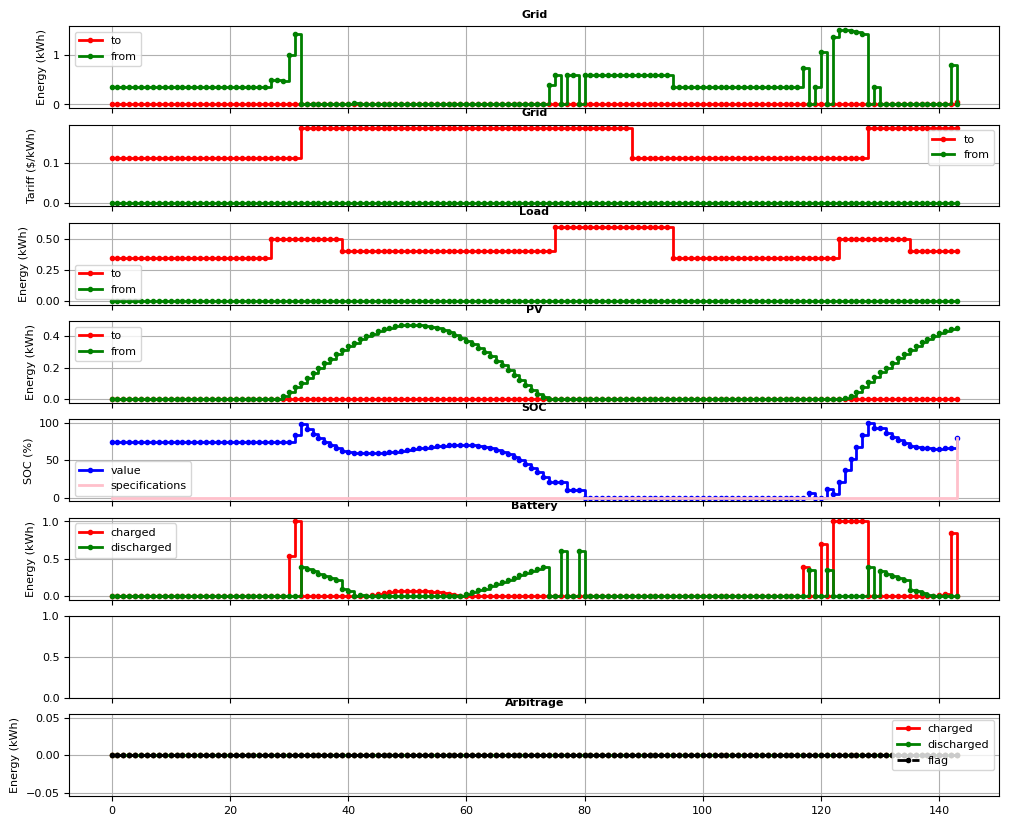

In [9]:
fig1, axs = plt.subplots(8, 1, sharex=True)

axs[0].step(t, grid_to, where='post', marker='o', linestyle='-', color = 'red')
axs[0].step(t, grid_from, where='post', marker='o', linestyle='-', color = 'green')
axs[0].set_ylabel("Energy (kWh)")
axs[0].set_title("Grid")
axs[0].legend(["to", "from"])

axs[1].step(t, tariff_to, where='post', marker='o', linestyle='-', color = 'red')
axs[1].step(t, tariff_from, where='post', marker='o', linestyle='-', color = 'green')
axs[1].set_ylabel("Tariff ($/kWh)")
axs[1].set_title("Grid")
axs[1].legend(["to", "from"])

axs[2].step(t, load_to, where='post', marker='o', linestyle='-', color = 'red')
axs[2].step(t, load_from, where='post', marker='o', linestyle='-', color = 'green')
axs[2].set_ylabel("Energy (kWh)")
axs[2].set_title("Load")
axs[2].legend(["to", "from"])

axs[3].step(t, pv_to, where='post', marker='o', linestyle='-', color = 'red')
axs[3].step(t, pv_from, where='post', marker='o', linestyle='-', color = 'green')
axs[3].set_ylabel("Energy (kWh)")
axs[3].set_title("PV")
axs[3].legend(["to", "from"])

axs[4].step(t, soc, where='post', marker='o', linestyle='-', color = 'blue')
axs[4].step(t, soc_specifications, where='post', linestyle='-', color = 'pink')
axs[4].set_ylabel("SOC (%)")
axs[4].set_title("SOC")
axs[4].legend(["value", "specifications"])

axs[5].step(t, charge,  where='post', marker='o', linestyle='-', color = 'red')
axs[5].step(t, discharge, where='post', marker='o', linestyle='-', color = 'green')
axs[5].set_ylabel("Energy (kWh)")
axs[5].set_title("Battery")
axs[5].legend(["charged", "discharged"])

# axs[6].step(t, solar_deficit,  where='post', marker='o', linestyle='-', color = 'red')
# axs[6].step(t, solar_surplus, where='post', marker='o', linestyle='-', color = 'green')
# axs[6].set_ylabel("Energy (kWh)")
# axs[6].set_title("Solar surplus/deficit")
# axs[6].legend(["deficit", "surplus"])

axs[7].step(t, charge_arbitrage,  where='post', marker='o', linestyle='-', color = 'red')
axs[7].step(t, discharge_arbitrage, where='post', marker='o', linestyle='-', color = 'green')
axs[7].step(t, flag_arbitrage, where='post', marker='o', linestyle='--', color = 'black')
axs[7].set_ylabel("Energy (kWh)")
axs[7].set_title("Arbitrage")
axs[7].legend(["charged", "discharged", "flag"])